# 02: Customer Feature Engineering, RFM Analysis & K-Means Segmentation
This notebook walks through calculating RFM and multi-dimensional engagement metrics, transforming skewed distributions with log1p and robust scaling, evaluating optimal K, and generating deterministic descriptive cluster profiles.

In [1]:
import sys, os
from pathlib import Path
import pandas as pd
import numpy as np

# Robust root resolver whether run from notebooks/ or workspace root
_curr = Path('.').resolve()
PROJECT_ROOT = _curr if (_curr / 'src').exists() else (_curr.parent if (_curr.parent / 'src').exists() else (_curr.parents[1] if len(_curr.parents) > 1 and (_curr.parents[1] / 'src').exists() else _curr))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Switch working directory to project root so all relative paths ('data/...', 'artifacts/...') resolve seamlessly
os.chdir(PROJECT_ROOT)

import matplotlib.pyplot as plt
from src.features.customer_features import CustomerFeatureEngineer
from src.segmentation.clustering import CustomerClustering
from src.segmentation.profiling import SegmentProfiler
from src.segmentation.visualization import SegmentVisualizer


## 1. Extract Customer Features & RFM Metrics on Train Split

In [2]:
train_events_df = pd.read_parquet('data/processed/train_events.parquet')
cust_fe = CustomerFeatureEngineer(scaler_type='robust')
features_df = cust_fe.extract_features(train_events_df)
transformed_df, scaled_matrix = cust_fe.transform_and_scale(features_df, fit=True)
features_df.head()


2026-10-09 06:57:41 [INFO] [customer_features:51] Computing customer features and RFM metrics...
2026-10-09 06:57:41 [INFO] [customer_features:121] Extracted customer features for 2996 customers.
2026-10-09 06:57:41 [INFO] [customer_features:126] Applying log1p transformations and robust scaling...


,customer_id,recency,frequency,monetary_value,average_order_value,average_basket_size,unique_products,unique_categories,category_diversity,discount_usage_rate,active_days,repeat_purchase_rate
0,20000,5.770428,13,222.630,58.0650,1.0,12,7,2.652462,0.000000,13,0.083333
1,20001,10.015625,19,1806.671,165.1462,1.0,15,6,2.002849,0.052632,18,0.133333
2,20002,106.461007,2,988.880,988.8800,1.0,2,2,1.820478,0.000000,2,0.000000
3,20003,2.683229,22,4353.350,501.3200,1.0,19,6,1.913574,0.045455,19,0.105263
4,20004,43.371944,7,1516.890,547.4300,1.0,7,4,1.923593,0.000000,7,0.000000


## 2. Evaluate Optimal K via Inertia & Silhouette Diagnostics

In [3]:
clustering = CustomerClustering(n_clusters=4, random_state=42)
diag = clustering.find_optimal_k(scaled_matrix, k_range=[2, 3, 4, 5, 6, 7, 8])
cluster_labels = clustering.fit_predict(scaled_matrix)
features_df['cluster'] = cluster_labels


2026-10-09 06:57:46 [INFO] [clustering:52] Evaluating optimal K over range [2, 3, 4, 5, 6, 7, 8]...
2026-10-09 06:57:49 [INFO] [clustering:70]   K=2: Inertia=18222.65, Silhouette=0.2777, Davies-Bouldin=1.3302
2026-10-09 06:57:49 [INFO] [clustering:70]   K=3: Inertia=13164.43, Silhouette=0.3228, Davies-Bouldin=1.0891
2026-10-09 06:57:49 [INFO] [clustering:70]   K=4: Inertia=10714.14, Silhouette=0.2937, Davies-Bouldin=1.1044
2026-10-09 06:57:49 [INFO] [clustering:70]   K=5: Inertia=9093.00, Silhouette=0.2875, Davies-Bouldin=1.1068
2026-10-09 06:57:50 [INFO] [clustering:70]   K=6: Inertia=8191.01, Silhouette=0.2792, Davies-Bouldin=1.1166
2026-10-09 06:57:50 [INFO] [clustering:70]   K=7: Inertia=7486.15, Silhouette=0.2669, Davies-Bouldin=1.1886
2026-10-09 06:57:50 [INFO] [clustering:70]   K=8: Inertia=6935.49, Silhouette=0.2397, Davies-Bouldin=1.1416
2026-10-09 06:57:50 [INFO] [clustering:77] Recommended K by silhouette score: 3 (score: 0.3228)
2026-10-09 06:57:50 [INFO] [clustering:82] Fi

## 3. Automated Deterministic Segment Profiling (No Hardcoding)

In [4]:
profiler = SegmentProfiler()
profiles_df, labels_map = profiler.profile_segments(features_df)
print("Discovered Customer Segments:")
print(profiles_df[['cluster_id', 'label', 'customer_count', 'percentage_of_customers', 'avg_monetary_value', 'avg_frequency', 'avg_recency_days']])


2026-10-09 06:57:56 [INFO] [segment_profiling:41] Computing deterministic cluster profiles and statistics...
Discovered Customer Segments:
   cluster_id                                label  customer_count  \
0           3  High-Value Frequent Active Shoppers            1365   
1           0   Low-Spend Dormant/At-Risk Shoppers            1134   
2           1   Low-Spend Dormant/At-Risk Shoppers             282   
3           2             Discount-Driven Shoppers             215   

   percentage_of_customers  avg_monetary_value  avg_frequency  \
0                    45.56             1482.91          18.38   
1                    37.85              356.22           5.56   
2                     9.41                0.46           2.51   
3                     7.18              892.84          10.12   

   avg_recency_days  
0              6.16  
1             36.50  
2             66.83  
3             22.97  


## 4. 2D PCA Dimensionality Reduction Projection

2026-10-09 06:58:33 [INFO] [segment_visualization:37] Computing 2D PCA projection for cluster visualization...
2026-10-09 06:58:40 [INFO] [segment_visualization:89] Saved PCA cluster visualization to outputs\figures\customer_segments_pca.png


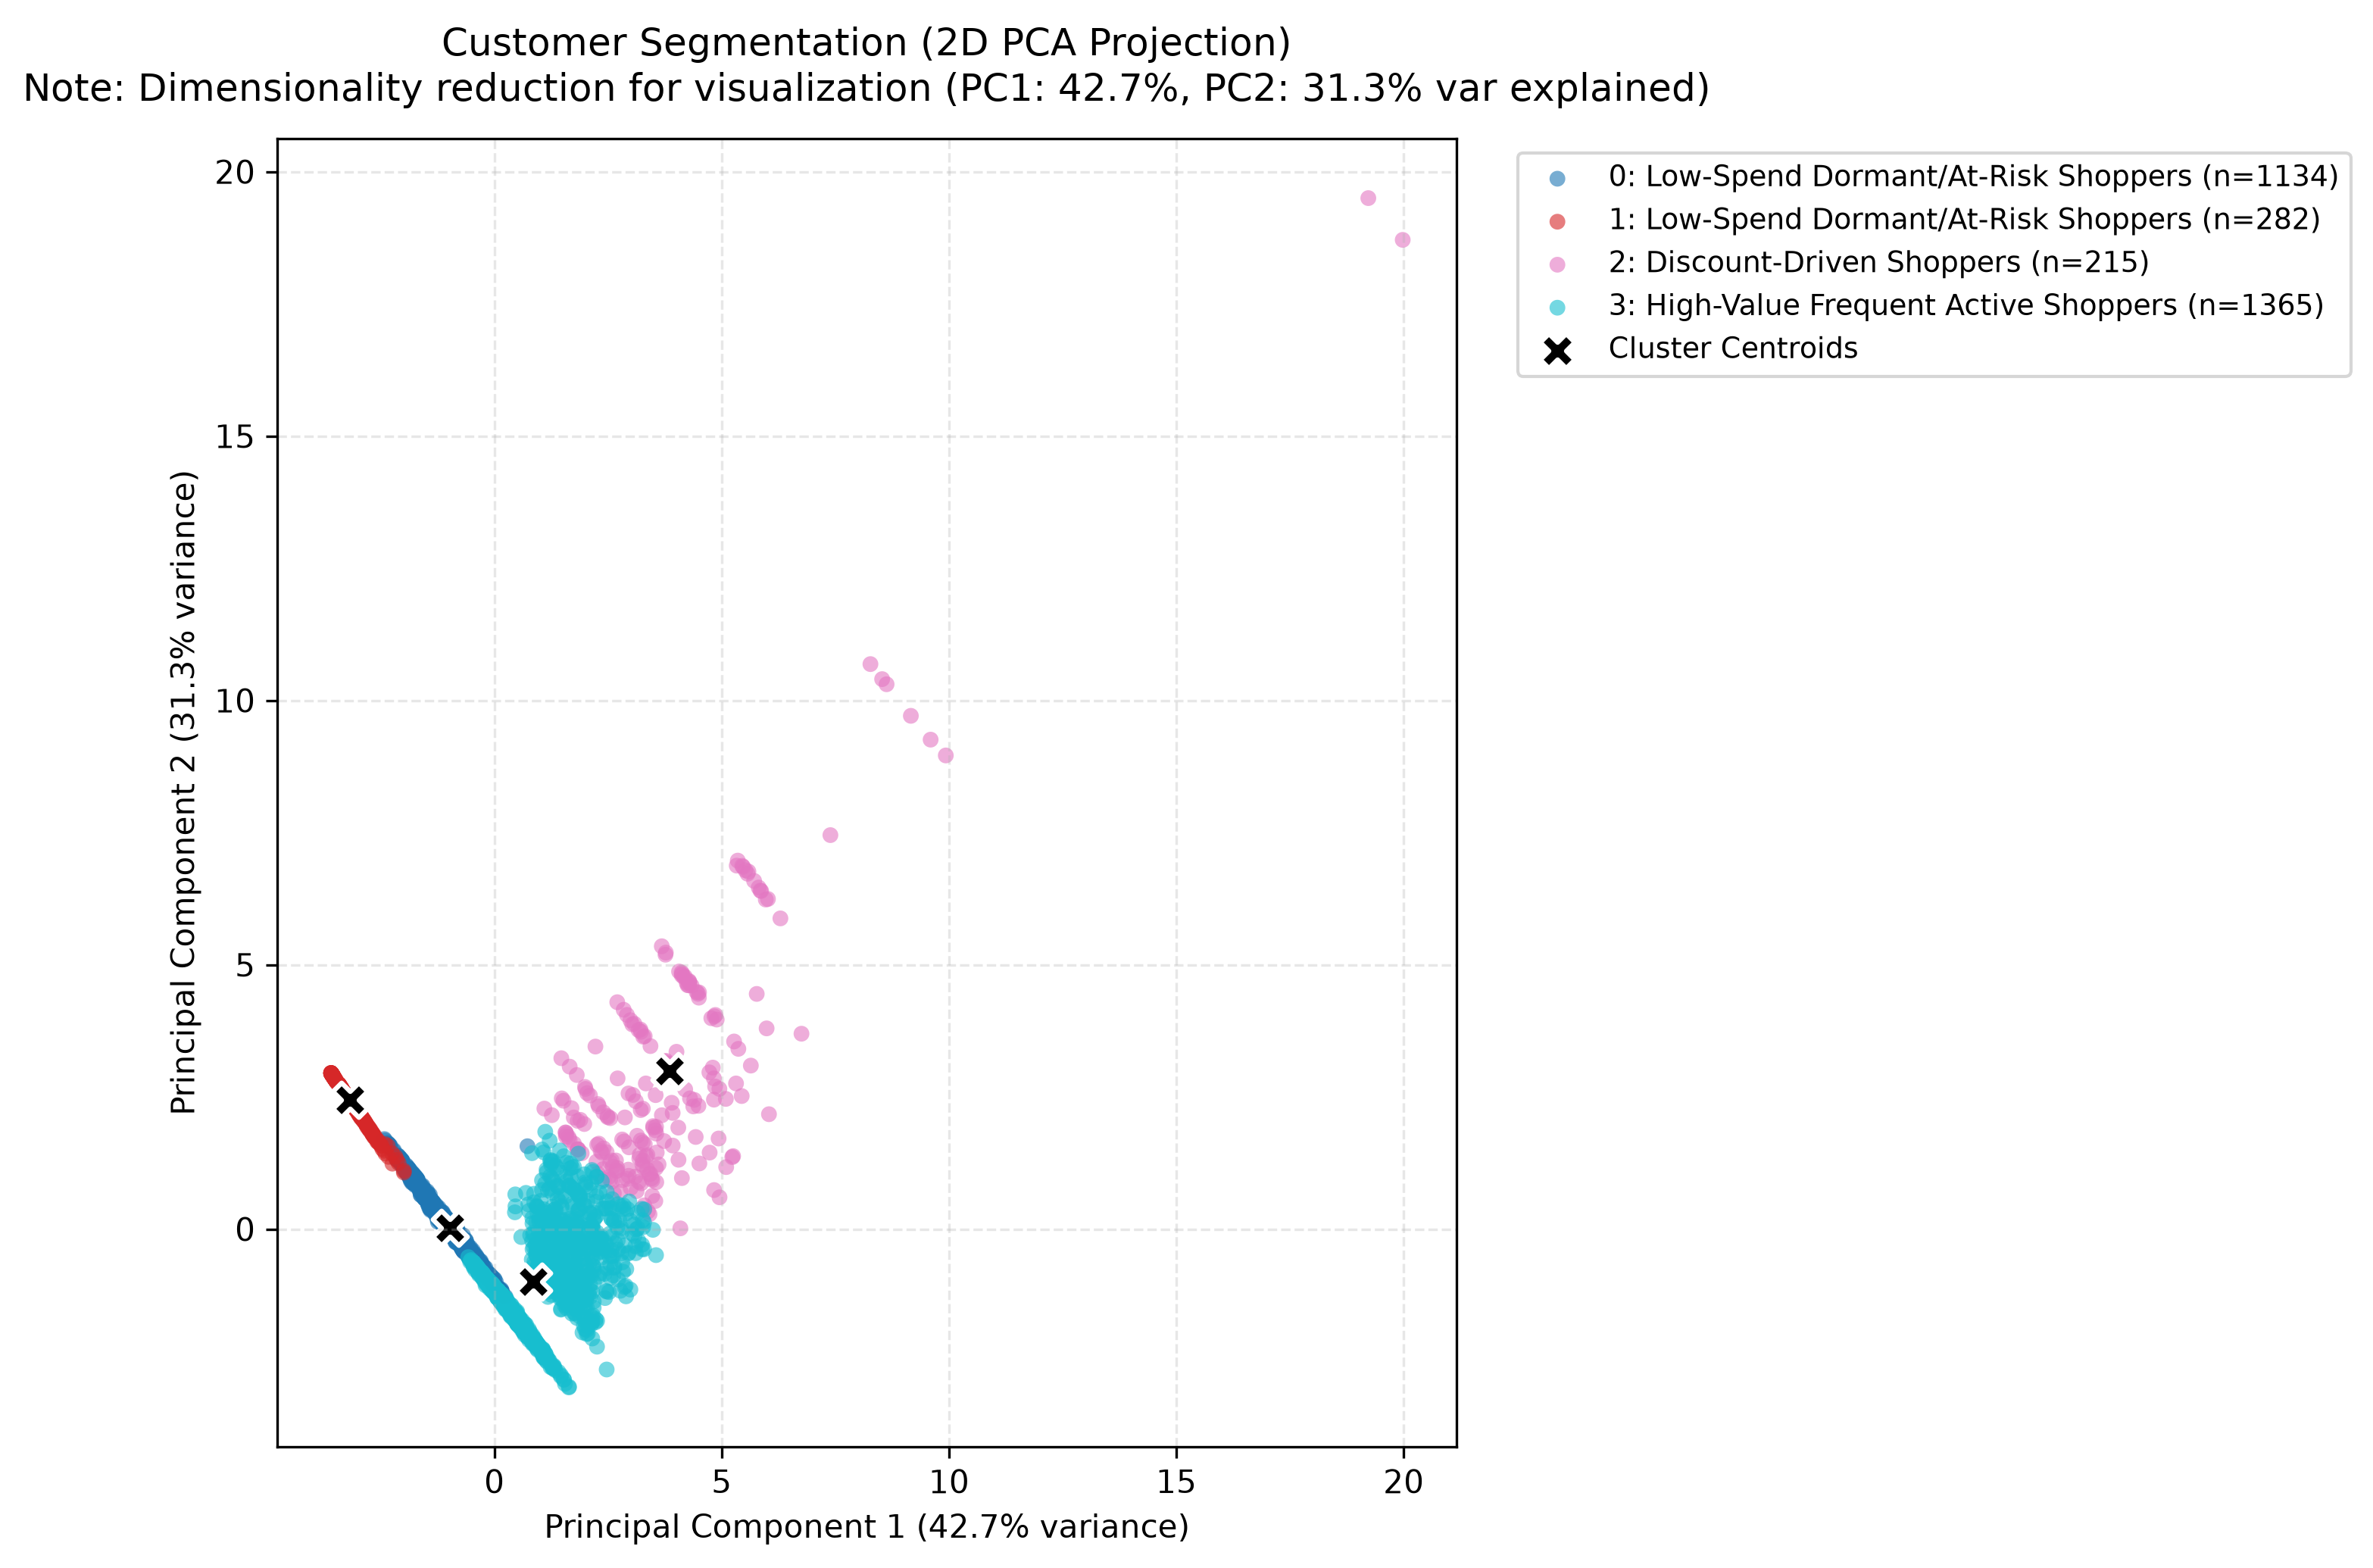

In [5]:
viz = SegmentVisualizer(n_components=2)
viz.plot_pca_clusters(scaled_matrix, cluster_labels, cluster_names=labels_map, output_image_path='outputs/figures/customer_segments_pca.png')
from IPython.display import Image
Image('outputs/figures/customer_segments_pca.png')
